# Flight Ticket Price – Data Analysis & Prediction
# By: Suchitra Thanumalayan

- **Part 1:** Data Analysis Report
- **Part 2:** Predictive model that helps customers predict flight prices and plan their journey
- **Part 3:** Suggestions for travellers on how to get a cheaper ticket

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_excel("Flight_Fare.xlsx")
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


# Part 1: Data Analysis Report
## 1. Basic Checks

In [3]:
df.shape

(10683, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB


In [5]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [6]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [7]:
df[df.isnull().any(axis=1)]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [8]:
df.duplicated().sum()

np.int64(220)

In [9]:
df.nunique()

Airline              12
Date_of_Journey      44
Source                5
Destination           6
Route               128
Dep_Time            222
Arrival_Time       1343
Duration            368
Total_Stops           5
Additional_Info      10
Price              1870
dtype: int64

In [10]:
for col in ['Airline', 'Source', 'Destination', 'Total_Stops', 'Additional_Info']:
    print(df[col].value_counts(), '\n')

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1752
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64 

Source
Delhi       4537
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381
Name: count, dtype: int64 

Destination
Cochin       4537
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64 

Total_Stops
1 stop      5625
non-stop    3491
2 stops     1520
3 stops       45
4 stops        1
Name: count, dtype: int64 

Additional_Info
No info                         8345
In-flight meal

In [11]:
# the dates are written in two ways, e.g. '01/03/2019' and '1/03/2019'
sorted(df['Date_of_Journey'].unique())[:12]

['01/03/2019',
 '03/03/2019',
 '06/03/2019',
 '09/03/2019',
 '1/03/2019',
 '1/04/2019',
 '1/05/2019',
 '1/06/2019',
 '12/03/2019',
 '12/04/2019',
 '12/05/2019',
 '12/06/2019']

In [12]:
# Arrival_Time sometimes has a date attached (next-day arrival), and Duration is text like '2h 50m'
df[['Dep_Time', 'Arrival_Time', 'Duration']].sample(8, random_state=1)

,Dep_Time,Arrival_Time,Duration
7931,22:45,00:10 16 Mar,1h 25m
5468,09:35,12:30,2h 55m
8618,16:30,04:40 10 Jun,12h 10m
3836,22:50,09:00 16 Mar,10h 10m
7771,21:10,18:15 22 May,21h 5m
3035,11:30,19:15,7h 45m
2785,13:20,16:10,2h 50m
4228,04:45,12:35,7h 50m


In [13]:
# a 2-stop flight that took only 5 minutes is impossible
df[df['Duration'] == '5m']

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
6474,Air India,6/03/2019,Mumbai,Hyderabad,BOM → GOI → PNQ → HYD,16:50,16:55,5m,2 stops,No info,17327


In [14]:
# Source and Destination always come in the same pairs
pd.crosstab(df['Source'], df['Destination'])

Destination,Banglore,Cochin,Delhi,Hyderabad,Kolkata,New Delhi
Source,,,,,,
Banglore,0,0,1265,0,0,932
Chennai,0,0,0,0,381,0
Delhi,0,4537,0,0,0,0
Kolkata,2871,0,0,0,0,0
Mumbai,0,0,0,697,0,0


**Observations**
- The data has **10,683 rows and 11 columns**. Each row is one flight ticket on a domestic Indian route, with its airline, journey date, route, times, duration, number of stops and **price in rupees** (the target).
- The file is an Excel file (`.xlsx`), so it is read with `pd.read_excel`, which needs the `openpyxl` package.
- Only **1 row has missing values** (`Route` and `Total_Stops`, Air India Delhi to Cochin).
- There are **220 duplicate rows**.
- Every column except `Price` is stored as **text**, including dates, times and duration (e.g. `'2h 50m'`), so they have to be converted to numbers.
- `Date_of_Journey` is written in two ways (`'01/03/2019'` and `'1/03/2019'`), so there seem to be 44 dates when there are really only **40 journey dates, from 1 March to 27 June 2019** (every 3 days).
- `Arrival_Time` sometimes has a date attached (`'01:10 22 Mar'`), meaning the flight lands the next day.
- `Destination` uses both **`'Delhi'` and `'New Delhi'`** for the same city, and `Additional_Info` uses both `'No info'` and `'No Info'`.
- One flight with 2 stops (Mumbai to Hyderabad via Goa and Pune) has a **duration of 5 minutes**, which is impossible.
- **Each source city always flies to the same destination**, so there are only **5 routes**: Delhi to Cochin, Kolkata to Banglore, Banglore to Delhi, Mumbai to Hyderabad and Chennai to Kolkata.
- `Price` goes from **Rs 1,759 to Rs 79,512**. The very high prices are Jet Airways Business class tickets.

## Cleaning The Data

In [15]:
# remove duplicate rows and the single row with missing Route / Total_Stops
df = df.drop_duplicates()
df = df.dropna()

# remove the impossible 5-minute flight
df = df[df['Duration'] != '5m']

# 'New Delhi' and 'Delhi' are the same city; 'No Info' and 'No info' are the same value
df['Destination'] = df['Destination'].replace('New Delhi', 'Delhi')
df['Additional_Info'] = df['Additional_Info'].replace('No Info', 'No info')

# journey date -> day, month and day of the week (dayfirst because the format is dd/mm/yyyy)
date = pd.to_datetime(df['Date_of_Journey'], dayfirst=True)
df['JOURNEY DAY'] = date.dt.day
df['JOURNEY MONTH'] = date.dt.month
df['WEEKDAY'] = date.dt.day_name()

# departure and arrival hour (Arrival_Time can be '01:10 22 Mar', so keep only the first 5 characters)
df['DEP HOUR'] = pd.to_datetime(df['Dep_Time'], format='%H:%M').dt.hour
df['ARR HOUR'] = pd.to_datetime(df['Arrival_Time'].str[:5], format='%H:%M').dt.hour
df['NEXT DAY ARRIVAL'] = (df['Arrival_Time'].str.len() > 5).astype(int)

# duration text '2h 50m' -> minutes
def to_minutes(text):
    hours, minutes = 0, 0
    for part in text.split():
        if part.endswith('h'):
            hours = int(part[:-1])
        else:
            minutes = int(part[:-1])
    return hours * 60 + minutes
df['DURATION MINS'] = df['Duration'].apply(to_minutes)

# number of stops as a number
df['STOPS'] = df['Total_Stops'].map({'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4})

# route name for the plots
df['ROUTE NAME'] = df['Source'] + ' - ' + df['Destination']

df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,JOURNEY DAY,JOURNEY MONTH,WEEKDAY,DEP HOUR,ARR HOUR,NEXT DAY ARRIVAL,DURATION MINS,STOPS,ROUTE NAME
0,IndiGo,24/03/2019,Banglore,Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,Sunday,22,1,1,170,0,Banglore - Delhi
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,Wednesday,5,13,0,445,2,Kolkata - Banglore
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,Sunday,9,4,1,1140,2,Delhi - Cochin
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,Sunday,18,23,0,325,1,Kolkata - Banglore
4,IndiGo,01/03/2019,Banglore,Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,Friday,16,21,0,285,1,Banglore - Delhi


In [16]:
df.shape

(10461, 20)

In [17]:
df.isnull().sum().sum(), df.duplicated().sum()

(np.int64(0), np.int64(0))

After cleaning there are **10,461 rows, no missing values and no duplicates**. New number columns were made from the text columns: journey day, month and weekday, departure and arrival hour, a next-day-arrival flag, duration in minutes and number of stops.

## 2. Histogram

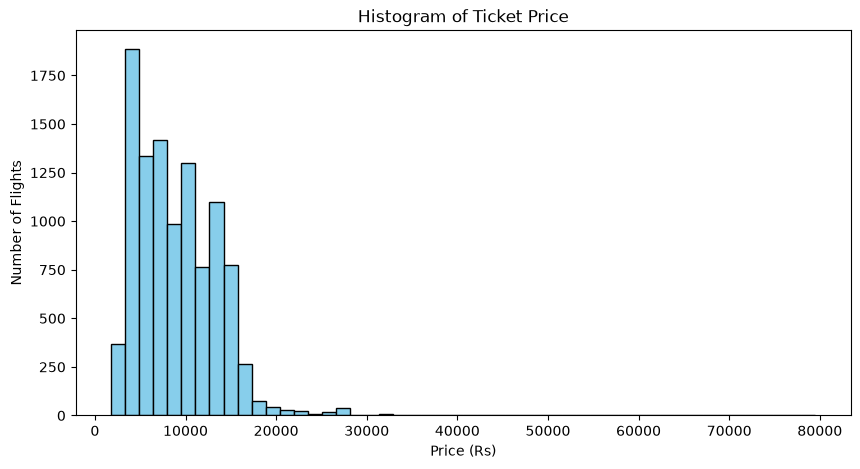

In [18]:
plt.figure(figsize=(10,5))
plt.hist(df['Price'], bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Ticket Price')
plt.xlabel('Price (Rs)')
plt.ylabel('Number of Flights')
plt.show()

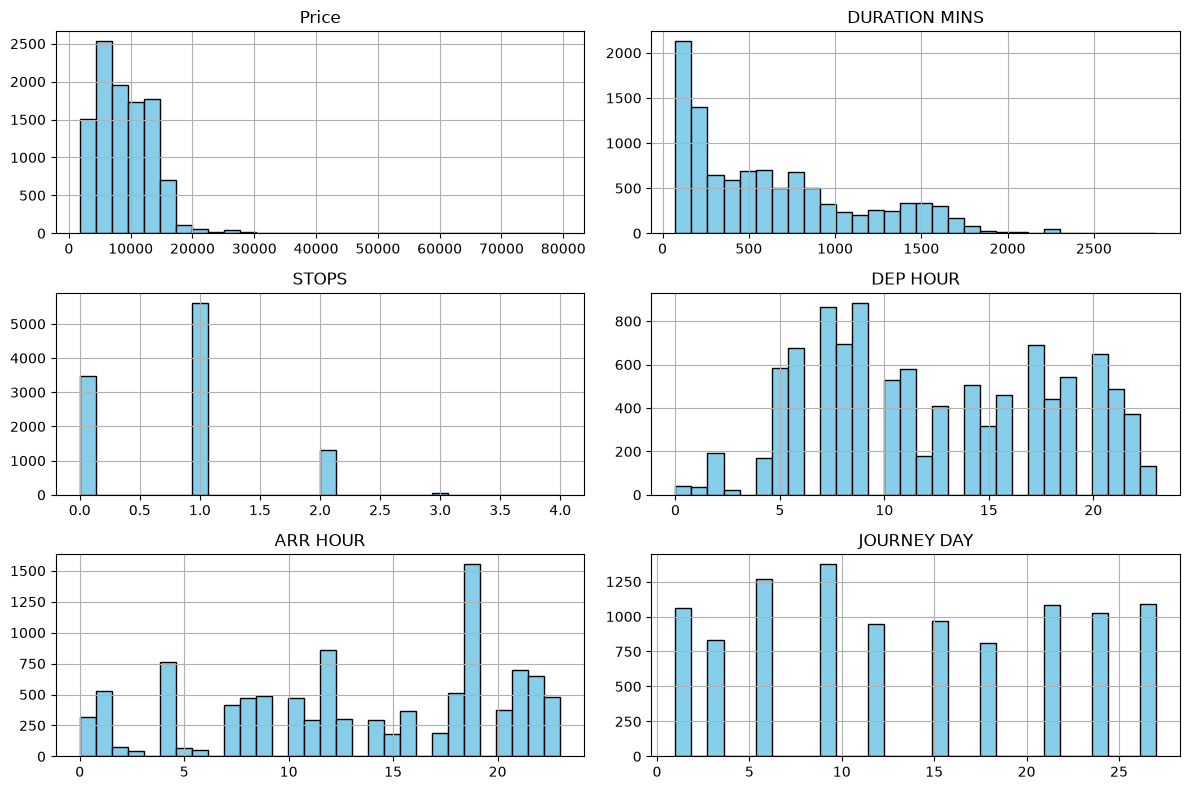

In [19]:
df[['Price', 'DURATION MINS', 'STOPS', 'DEP HOUR', 'ARR HOUR', 'JOURNEY DAY']].hist(figsize=(12,8), bins=30, color='skyblue', edgecolor='black')
plt.tight_layout()
plt.show()

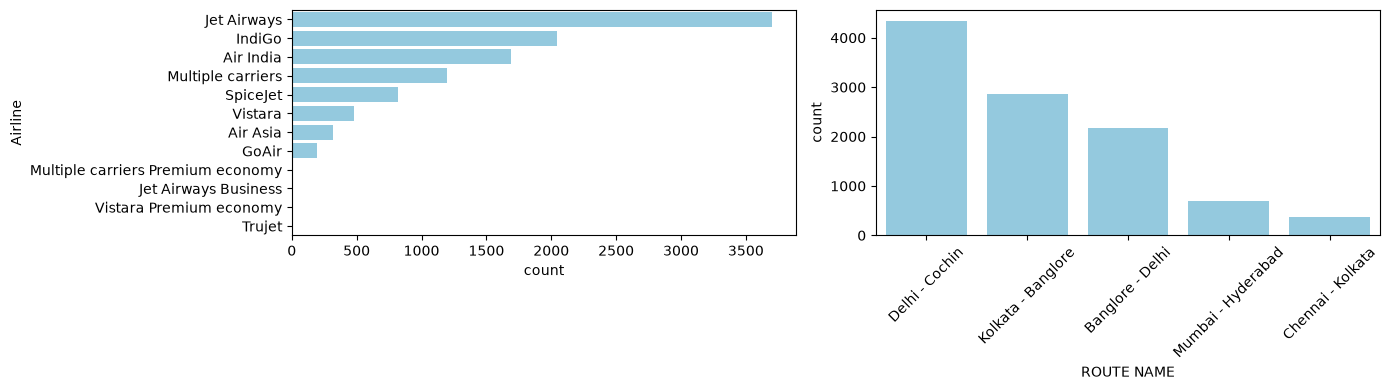

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.countplot(data=df, y='Airline', order=df['Airline'].value_counts().index, color='skyblue', ax=axes[0])
sns.countplot(data=df, x='ROUTE NAME', order=df['ROUTE NAME'].value_counts().index, color='skyblue', ax=axes[1])
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [21]:
df['Price'].skew()

np.float64(1.8582213249556447)

**Insights:** The ticket price is **right-skewed** (skew 1.86): **90% of tickets cost between Rs 3,000 and Rs 15,000** and the median is about **Rs 8,300**, but a small number go above Rs 20,000 (up to Rs 79,512). Duration is also right-skewed: most flights take under 5 hours, but flights with long stopovers can take more than a day. **54% of flights have 1 stop, 33% are non-stop** and 13% have 2 stops. **Jet Airways** has the most tickets (3,700), followed by IndiGo and Air India, and **Delhi to Cochin** is by far the biggest route (4,345 tickets).

## 3. Relational Plots

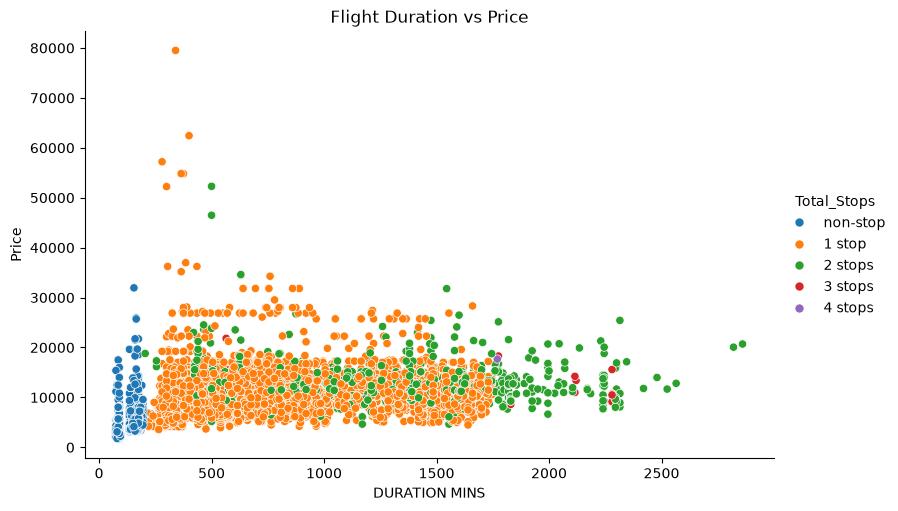

In [22]:
sns.relplot(data=df, x='DURATION MINS', y='Price', hue='Total_Stops', height=5, aspect=1.6,
            hue_order=['non-stop', '1 stop', '2 stops', '3 stops', '4 stops'])
plt.title('Flight Duration vs Price')
plt.show()

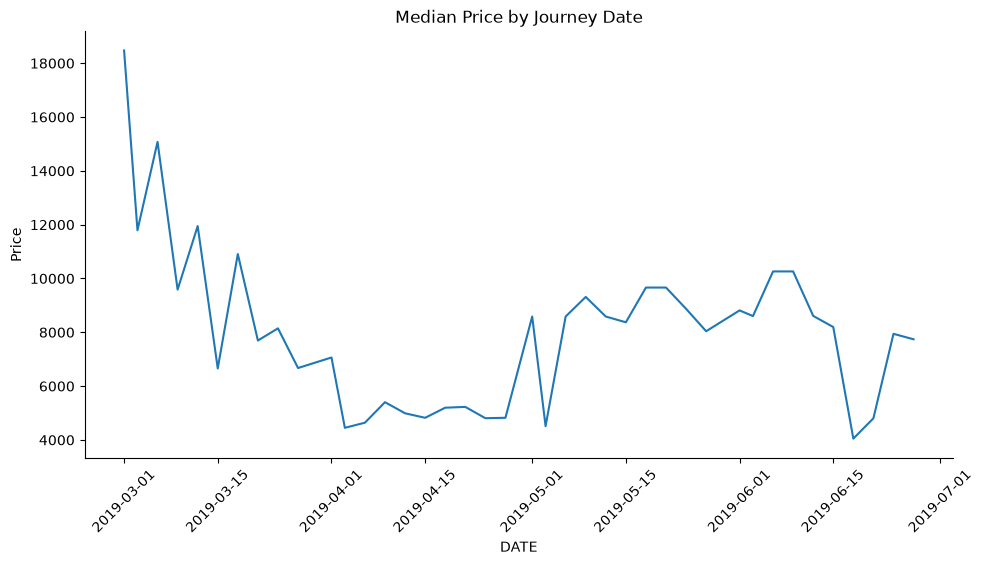

In [23]:
sns.relplot(data=df.assign(DATE=date), x='DATE', y='Price', kind='line', estimator='median', errorbar=None, height=5, aspect=2)
plt.title('Median Price by Journey Date')
plt.xticks(rotation=45)
plt.show()

**Insights:** Price generally goes up with duration, but the main driver is the **number of stops**: non-stop flights (blue) are short and cheap, while flights with 1 or 2 stops are longer and cost much more. The price by journey date shows a strong pattern: flights in **early March are very expensive** (median about Rs 18,500 on 1 March), prices fall through March, are **lowest in April**, and go back up in May and June.

## 4. Pair Plot (Multivariate Analysis)

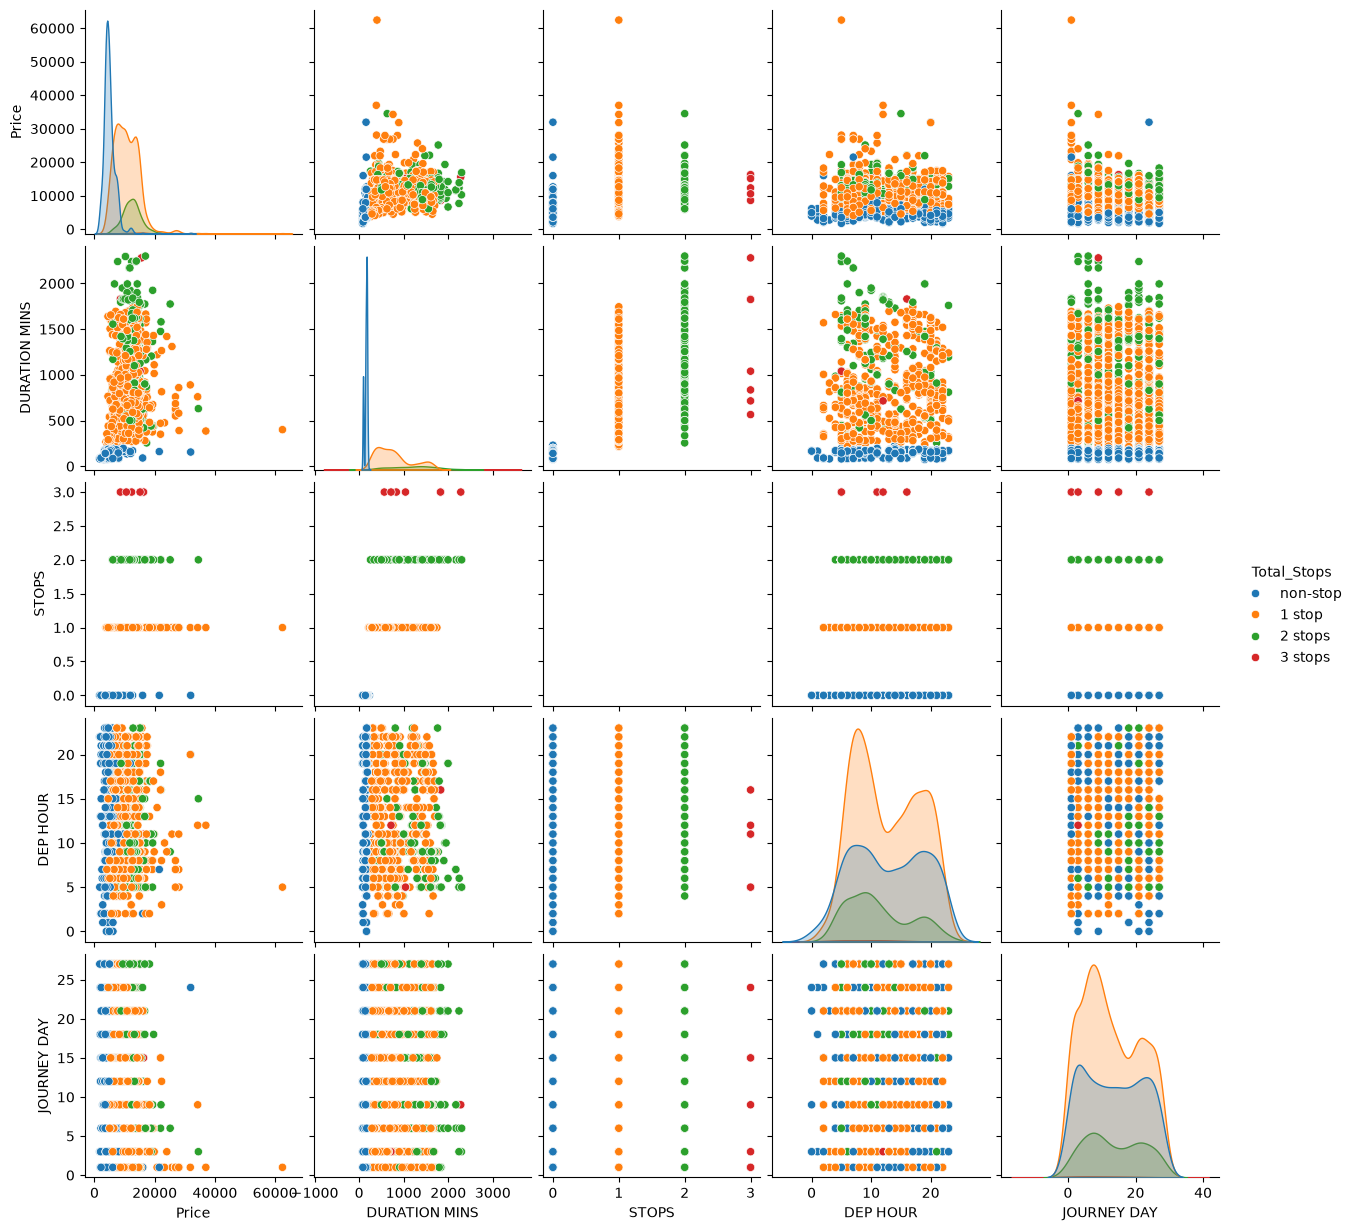

In [24]:
sns.pairplot(df[['Price', 'DURATION MINS', 'STOPS', 'DEP HOUR', 'JOURNEY DAY', 'Total_Stops']].sample(2000, random_state=1),
             hue='Total_Stops', hue_order=['non-stop', '1 stop', '2 stops', '3 stops'])
plt.show()

**Insights:** Number of stops and duration separate the prices most clearly: non-stop flights sit at the bottom of the price range, and 1-stop and 2-stop flights are spread higher. Departure hour and journey day have no straight-line relationship with price, so their effect (if any) has to come from combinations with other columns such as airline and route.

## 5. Data Preprocessing
### Boxplot

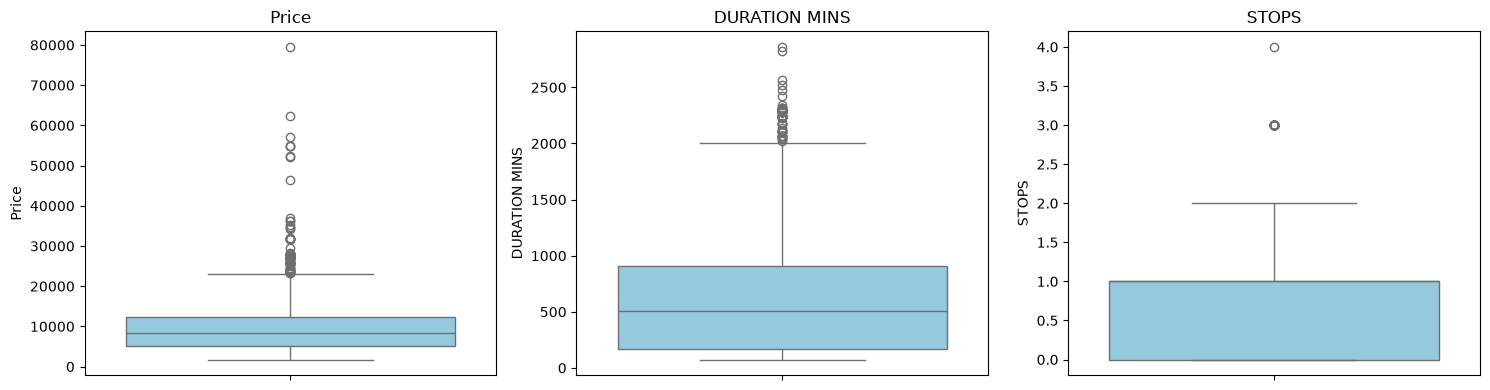

In [25]:
num_cols = ['Price', 'DURATION MINS', 'STOPS']
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

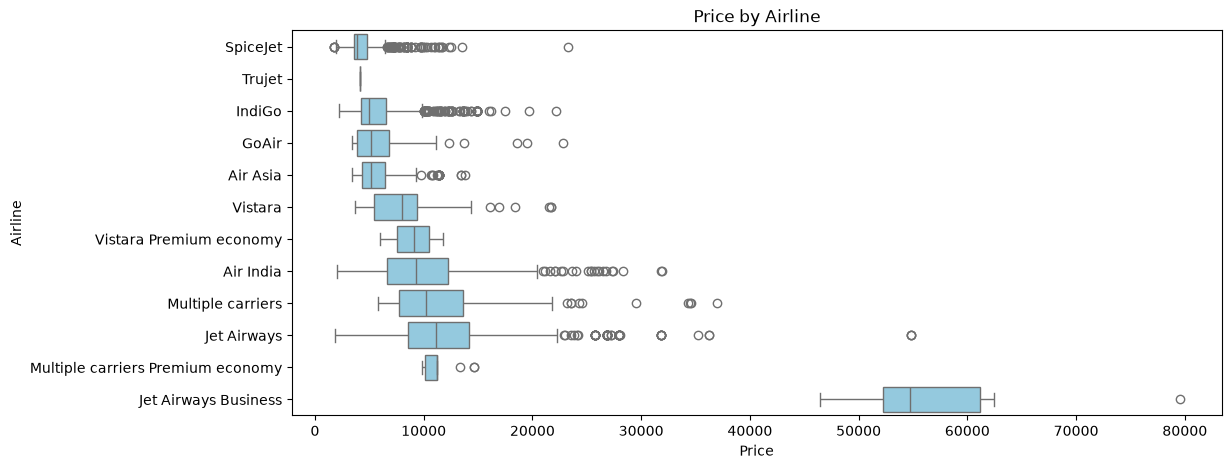

In [26]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df, y='Airline', x='Price', color='skyblue', order=df.groupby('Airline')['Price'].median().sort_values().index)
plt.title('Price by Airline')
plt.show()

In [27]:
# find outliers with the IQR method
for col in ['Price', 'DURATION MINS']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(col, '| upper limit:', upper, '| high outliers:', (df[col] > upper).sum(), '| max:', df[col].max())

Price | upper limit: 23016.5 | high outliers: 94 | max: 79512
DURATION MINS | upper limit: 2020.0 | high outliers: 75 | max: 2860


In [28]:
upper = df['Price'].quantile(0.75) + 1.5 * (df['Price'].quantile(0.75) - df['Price'].quantile(0.25))
df[df['Price'] > upper]['Airline'].value_counts()

Airline
Jet Airways             62
Air India               15
Multiple carriers       10
Jet Airways Business     6
SpiceJet                 1
Name: count, dtype: int64

In [29]:
df.sort_values('Price', ascending=False)[['Airline', 'Date_of_Journey', 'Route', 'Total_Stops', 'Additional_Info', 'Price']].head(8)

,Airline,Date_of_Journey,Route,Total_Stops,Additional_Info,Price
2924,Jet Airways Business,01/03/2019,BLR → BOM → DEL,1 stop,Business class,79512
5372,Jet Airways Business,01/03/2019,BLR → BOM → DEL,1 stop,Business class,62427
10364,Jet Airways Business,01/03/2019,BLR → MAA → DEL,1 stop,Business class,57209
1478,Jet Airways,18/03/2019,BLR → BOM → DEL,1 stop,No info,54826
5439,Jet Airways,01/03/2019,BLR → BOM → DEL,1 stop,No info,54826
2618,Jet Airways,18/03/2019,BLR → BOM → DEL,1 stop,No info,54826
9715,Jet Airways Business,6/03/2019,DEL → ATQ → BOM → COK,2 stops,No info,52285
657,Jet Airways Business,01/03/2019,BLR → BOM → DEL,1 stop,No info,52229


**Outliers**
- **Price:** 94 tickets are above the IQR upper limit of Rs 23,017 (max Rs 79,512). Most are **Jet Airways** (62) and all 6 **Jet Airways Business** tickets. They are real expensive tickets (business class, or bought for early March), not errors, so we **keep them**.
- **Duration:** 75 flights take more than about 34 hours (max 47h 40m). These are real flights with long overnight stopovers, so we **keep them**.

The only value that was a clear data error (the 5-minute flight) was already removed. Tree models are not thrown off by extreme values, so no other rows were removed.

### Line Plot

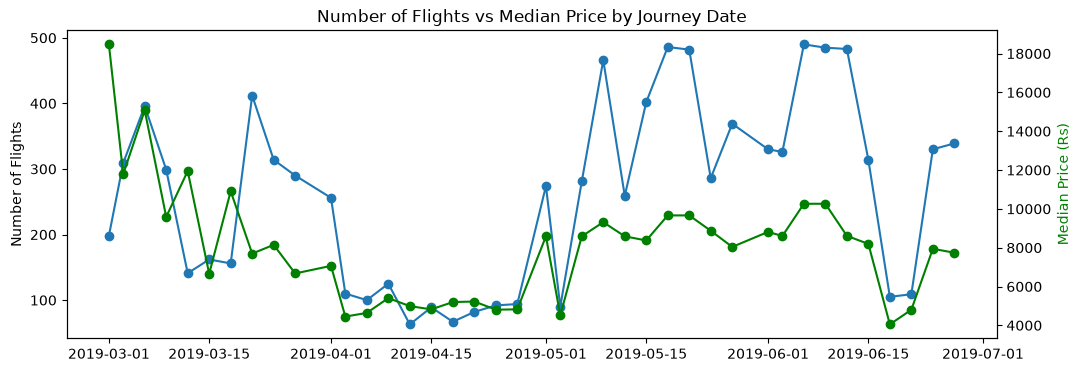

In [30]:
by_date = df.assign(DATE=date).groupby('DATE').agg(flights=('Price', 'count'), median_price=('Price', 'median'))

fig, ax1 = plt.subplots(figsize=(12,4))
ax1.plot(by_date.index, by_date['flights'], marker='o', label='Number of flights')
ax1.set_ylabel('Number of Flights')
ax2 = ax1.twinx()
ax2.plot(by_date.index, by_date['median_price'], marker='o', color='green', label='Median price')
ax2.set_ylabel('Median Price (Rs)', color='green')
plt.title('Number of Flights vs Median Price by Journey Date')
plt.show()

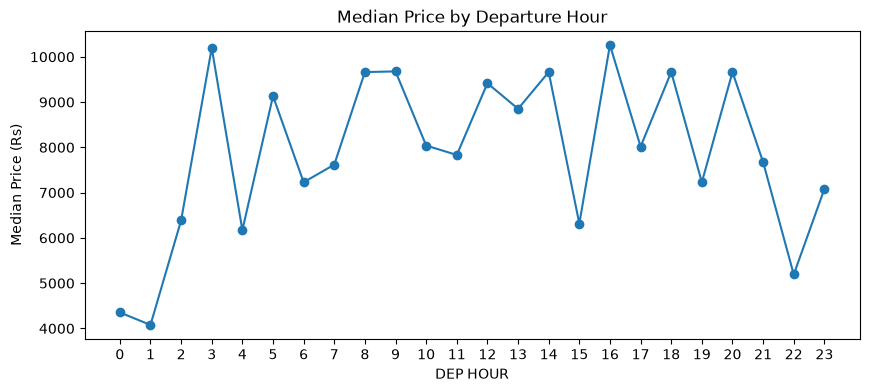

In [31]:
by_hour = df.groupby('DEP HOUR')['Price'].median()
by_hour.plot(marker='o', figsize=(10,4))
plt.title('Median Price by Departure Hour')
plt.ylabel('Median Price (Rs)')
plt.xticks(range(0, 24))
plt.show()

**Insights:**
- The number of tickets per date and the price move together: dates with many tickets (early March, May, June) are expensive, and the quiet dates (**April**, 3 May, 18 and 21 June) are cheap. Part of this is because the quiet dates mostly have tickets on the cheaper routes, so we check it route by route in Part 3.
- By departure hour, the cheapest flights leave **late at night (around midnight to 1 am, and at 10 pm)**, at about Rs 4,100 to 5,200. During the day the median moves up and down between about Rs 7,000 and Rs 10,000 with no clear pattern.

### Barplot

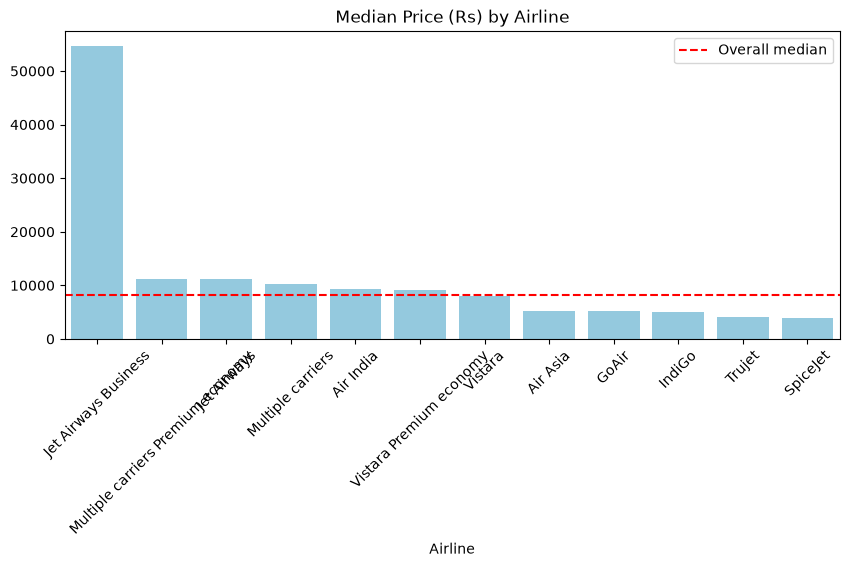

In [32]:
def price_plot(col, order=None):
    price = df.groupby(col)['Price'].median()
    price = price.reindex(order) if order else price.sort_values(ascending=False)
    plt.figure(figsize=(10,4))
    sns.barplot(x=price.index.astype(str), y=price.values, color='skyblue')
    plt.axhline(df['Price'].median(), color='red', linestyle='--', label='Overall median')
    plt.title('Median Price (Rs) by ' + col)
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

price_plot('Airline')

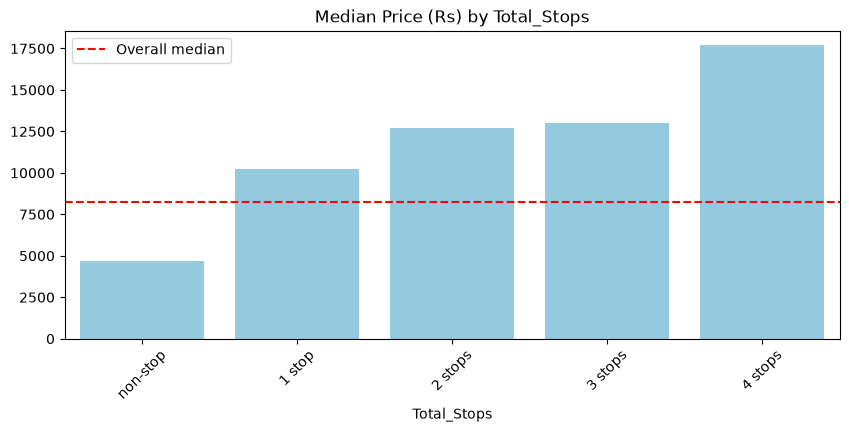

In [33]:
price_plot('Total_Stops', ['non-stop', '1 stop', '2 stops', '3 stops', '4 stops'])

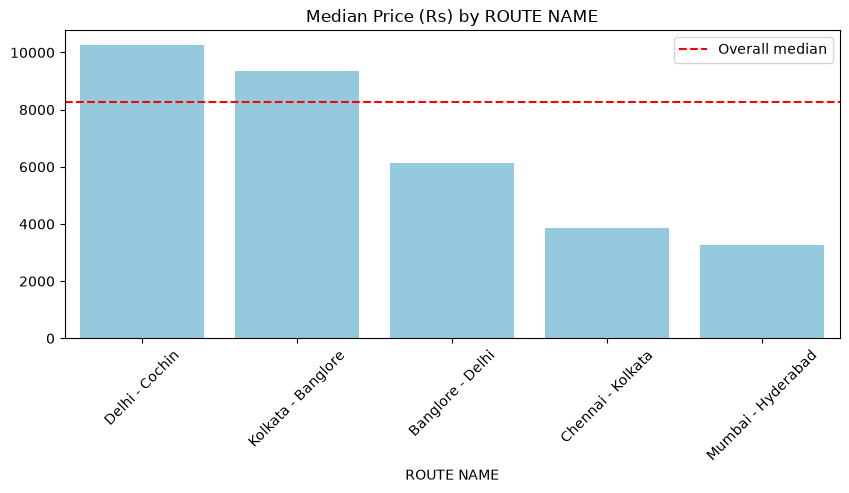

In [34]:
price_plot('ROUTE NAME')

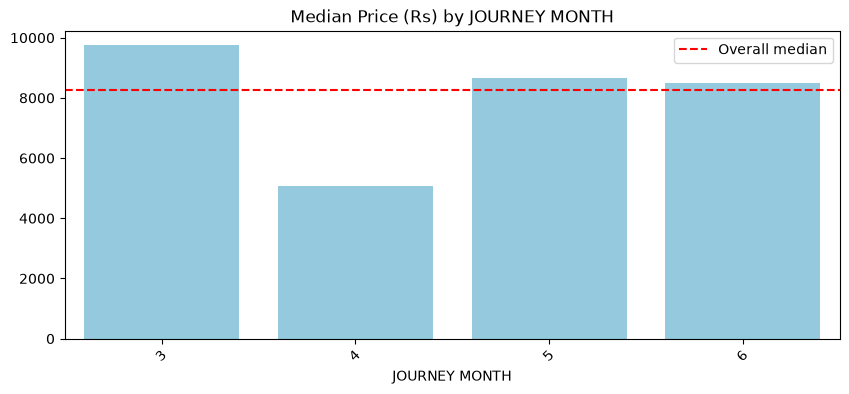

In [35]:
price_plot('JOURNEY MONTH', [3, 4, 5, 6])

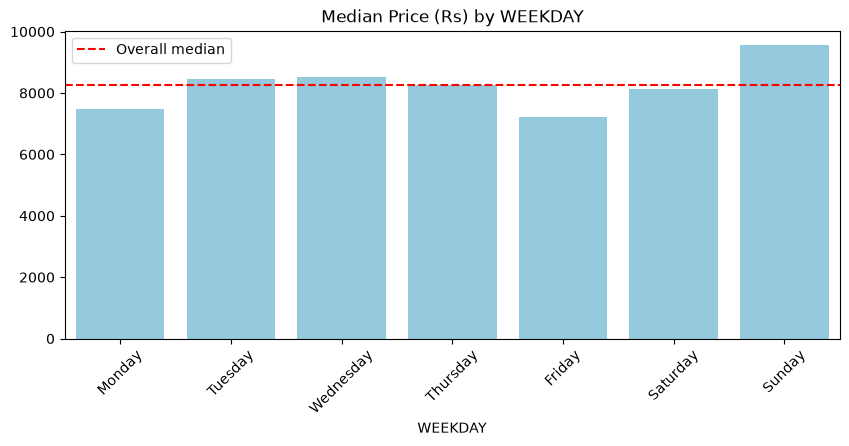

In [36]:
price_plot('WEEKDAY', ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

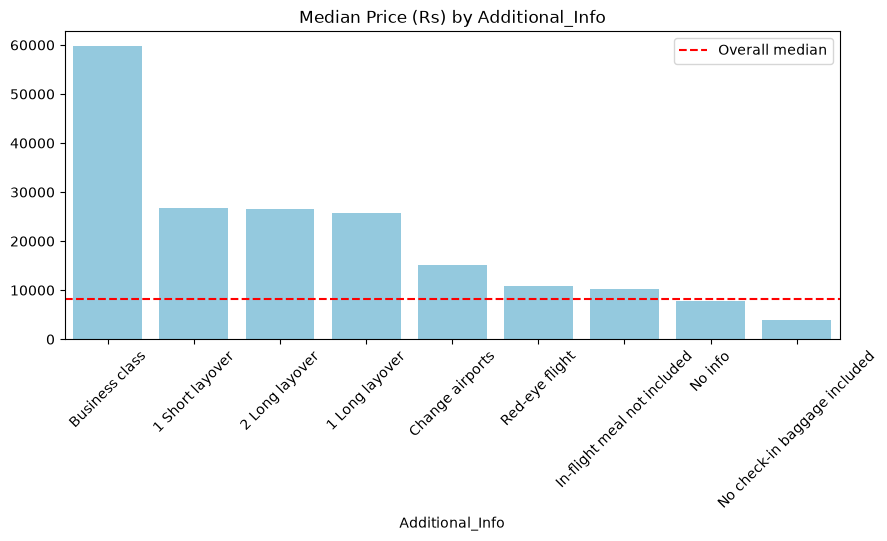

In [37]:
price_plot('Additional_Info')

**Insights** (red line = overall median price of about Rs 8,300)
- **Airline:** the low-cost airlines are cheapest: **SpiceJet (Rs 3,873)**, IndiGo (Rs 5,000), GoAir and Air Asia (about Rs 5,150). **Jet Airways (Rs 11,134)**, Multiple carriers (Rs 10,197) and Air India (Rs 9,292) are the most expensive normal tickets. **Jet Airways Business** costs about **Rs 54,700**.
- **Stops:** **non-stop flights are the cheapest (Rs 4,667)**, and the price more than doubles with 1 stop (Rs 10,262) and goes up again with 2 or 3 stops.
- **Route:** Delhi to Cochin (Rs 10,262) and Kolkata to Banglore (Rs 9,345) are the most expensive; Mumbai to Hyderabad (Rs 3,276) and Chennai to Kolkata (Rs 3,850) are the cheapest.
- **Month:** **April is the cheapest month (Rs 5,073)** and March the most expensive (Rs 9,748).
- **Weekday:** **Sunday is the most expensive day (Rs 9,555)**; Friday and Monday are the cheapest.
- **Additional info:** tickets with **no check-in baggage** are the cheapest (Rs 3,841). Business class and long layovers are the most expensive.

*Note: some of these groups mix different routes and airlines (for example, most April tickets are on cheaper routes). We check this in Part 3 by comparing within the same route.*

### Encoding
Machine learning models need numbers, so we convert the text columns into numbers with `LabelEncoder`. `Total_Stops` was already mapped to 0, 1, 2, 3, 4 by hand, because LabelEncoder sorts alphabetically and would put `'non-stop'` after `'4 stops'`.

In [38]:
from sklearn.preprocessing import LabelEncoder

data = df.drop(columns=['Date_of_Journey', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'ROUTE NAME']).copy()
le = LabelEncoder()
for col in ['Airline', 'Source', 'Destination', 'Route', 'Additional_Info', 'WEEKDAY']:
    data[col] = le.fit_transform(data[col])
data.head()

,Airline,Source,Destination,Route,Additional_Info,Price,JOURNEY DAY,JOURNEY MONTH,WEEKDAY,DEP HOUR,ARR HOUR,NEXT DAY ARRIVAL,DURATION MINS,STOPS
0,3,0,2,18,7,3897,24,3,3,22,1,1,170,0
1,1,3,0,84,7,7662,1,5,6,5,13,0,445,2
2,4,2,1,118,7,13882,9,6,3,9,4,1,1140,2
3,3,3,0,91,7,6218,12,5,3,18,23,0,325,1
4,3,0,2,29,7,13302,1,3,0,16,21,0,285,1


## 6. Feature Selection & Heat Map

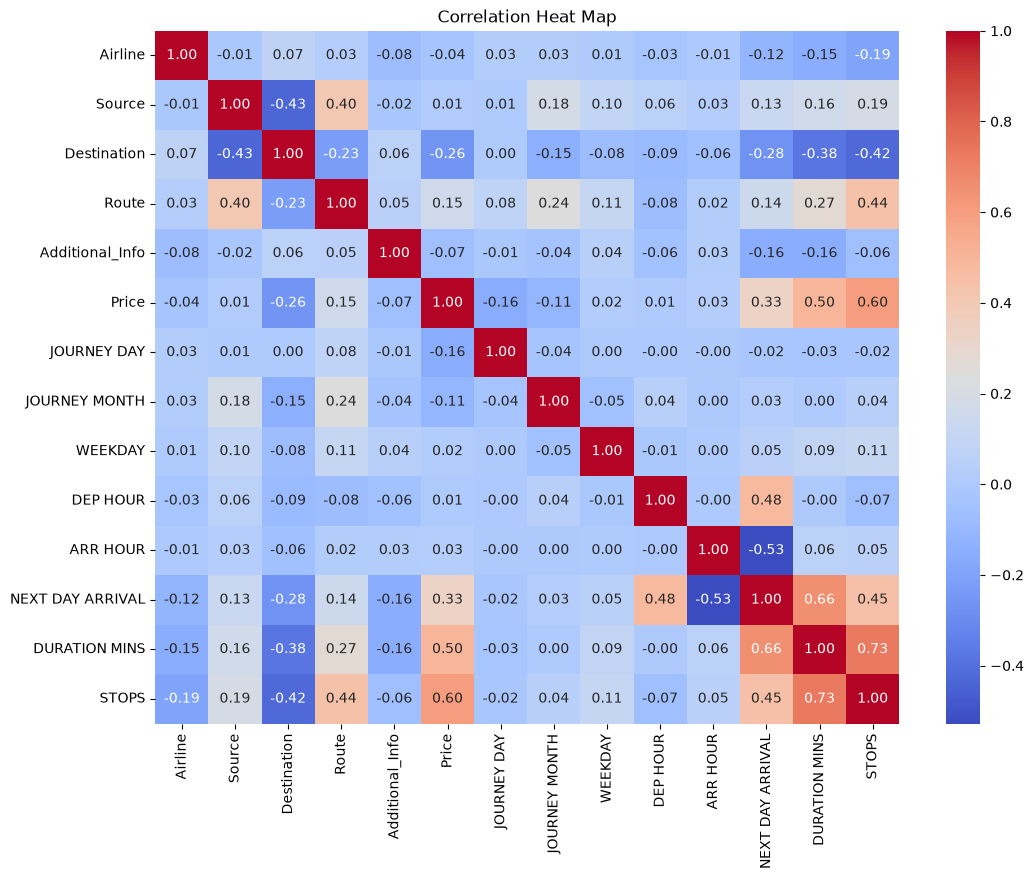

In [39]:
plt.figure(figsize=(12,9))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heat Map')
plt.show()

In [40]:
data.corr()['Price'].sort_values(ascending=False)

Price               1.000000
STOPS               0.601889
DURATION MINS       0.502087
NEXT DAY ARRIVAL    0.333301
Route               0.154530
ARR HOUR            0.030963
WEEKDAY             0.015065
Source              0.013504
DEP HOUR            0.005050
Airline            -0.036283
Additional_Info    -0.067300
JOURNEY MONTH      -0.113174
JOURNEY DAY        -0.158923
Destination        -0.261136
Name: Price, dtype: float64

In [41]:
data[['STOPS', 'DURATION MINS', 'NEXT DAY ARRIVAL']].corr()

,STOPS,DURATION MINS,NEXT DAY ARRIVAL
STOPS,1.000000,0.728367,0.445444
DURATION MINS,0.728367,1.000000,0.657784
NEXT DAY ARRIVAL,0.445444,0.657784,1.000000


In [42]:
# each Source always flies to the same Destination, so Destination adds no new information
df.groupby('Source')['Destination'].nunique()

Source
Banglore    1
Chennai     1
Delhi       1
Kolkata     1
Mumbai      1
Name: Destination, dtype: int64

**Feature selection**
- `STOPS` (0.60) and `DURATION MINS` (0.50) have the strongest correlation with price. They are related (0.73), but not the same: two flights with 1 stop can have very different stopover times, so both are kept.
- `Destination` is dropped, because **each source city always flies to the same destination**, so it has exactly the same information as `Source`.
- `Route` is kept even though it has 128 values, because it tells the model **which city the flight stops in** (e.g. via Mumbai or via Nagpur), which `Source` and `STOPS` alone do not.
- The original text columns (`Date_of_Journey`, `Dep_Time`, `Arrival_Time`, `Duration`, `Total_Stops`) were replaced by their number versions.
- The features kept are: `Airline`, `Source`, `Route`, `Additional_Info`, `JOURNEY DAY`, `JOURNEY MONTH`, `WEEKDAY`, `DEP HOUR`, `ARR HOUR`, `NEXT DAY ARRIVAL`, `DURATION MINS`, `STOPS`.

# Part 2: Predictive Model

## Which algorithm suits this data best?
We want to predict the **ticket price**, which is a number, so this is a **supervised regression** problem.
- Logistic Regression and Naive Bayes are for classification (yes / no answers), so they don't fit.
- K-Means and PCA are unsupervised, so they don't fit.
- SVM (SVR) is slow and needs a lot of tuning.
- Linear Regression, Decision Tree, KNN, Random Forest and Gradient Boosting can all predict numbers, so we try all five and compare them.

We judge the models on **R²** (how much of the variation in price the model explains, 1.0 is perfect), **MAE** (the average error in rupees), **RMSE** (like MAE but punishes big mistakes more) and **MAPE** (the average error as a percentage of the price).

**Expected Best: Random Forest or Gradient Boosting**, because price depends on combinations of features (e.g. the same airline is cheap on one route and expensive on another) and tree models handle mixed numeric and category data well.

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.drop(columns=['Price', 'Destination'])
y = data['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# scale the features (needed for Linear Regression and KNN, does not change tree models)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
print('Median price in train:', y_train.median(), '| in test:', y_test.median())

(8368, 12) (2093, 12)
Median price in train: 8366.0 | in test: 7927.0


In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=3, random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)
    results.append([name, r2_score(y_train, model.predict(X_train_s)), r2_score(y_test, y_pred),
                    mean_absolute_error(y_test, y_pred), np.sqrt(mean_squared_error(y_test, y_pred)),
                    mean_absolute_percentage_error(y_test, y_pred) * 100])

results = pd.DataFrame(results, columns=['Model', 'Train R2', 'Test R2', 'MAE', 'RMSE', 'MAPE %'])
results.sort_values('Test R2', ascending=False).round(3)

,Model,Train R2,Test R2,MAE,RMSE,MAPE %
3,Random Forest,0.979,0.891,704.443,1502.708,8.111
4,Gradient Boosting,0.841,0.830,1229.652,1874.602,15.121
1,Decision Tree,0.911,0.811,914.552,1975.639,10.306
2,KNN,0.838,0.746,1390.338,2291.276,17.907
0,Linear Regression,0.431,0.454,2484.439,3360.500,32.861


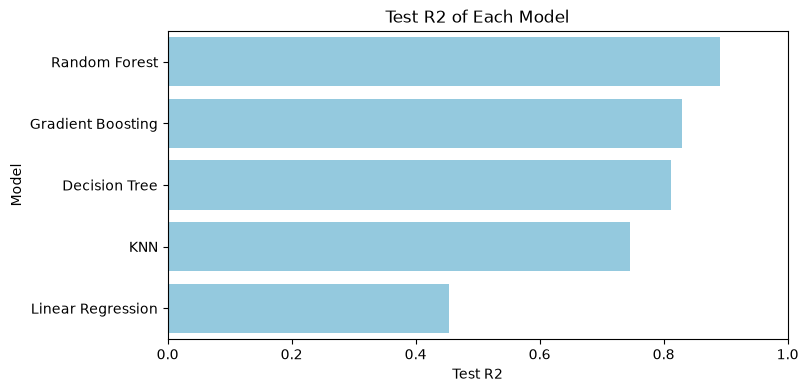

In [45]:
plt.figure(figsize=(8,4))
sns.barplot(data=results.sort_values('Test R2', ascending=False), x='Test R2', y='Model', color='skyblue')
plt.title('Test R2 of Each Model')
plt.xlim(0, 1)
plt.show()

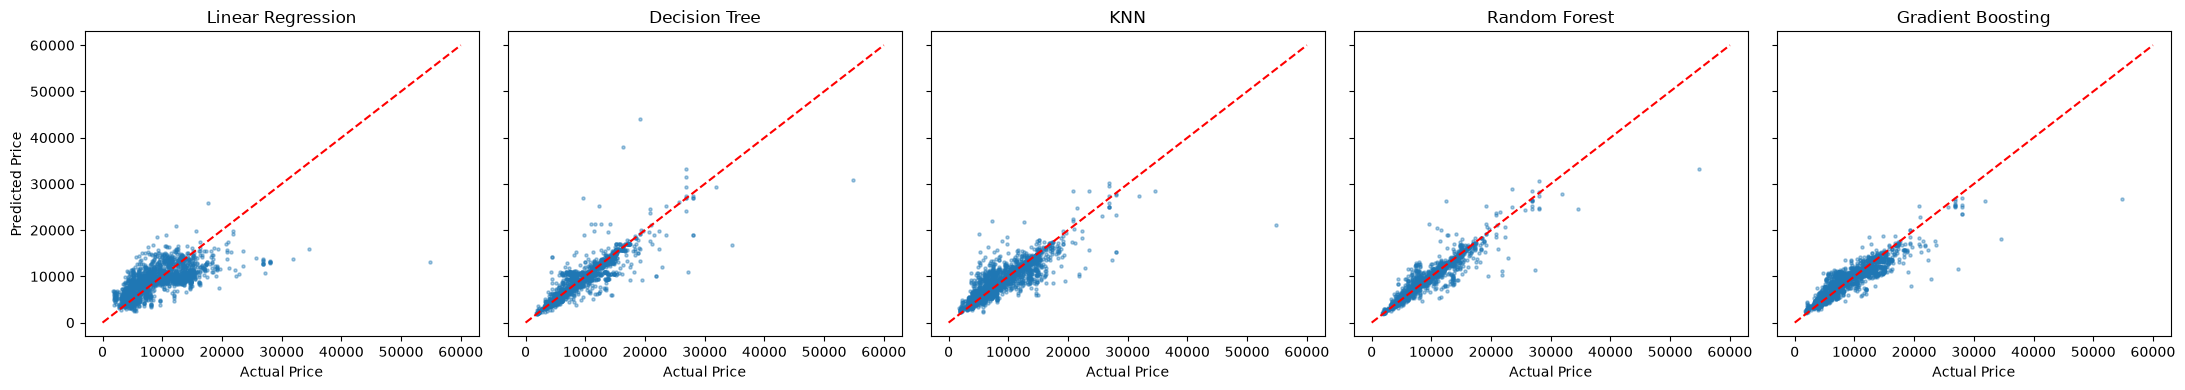

In [46]:
fig, axes = plt.subplots(1, 5, figsize=(22,4), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(y_test, model.predict(X_test_s), s=5, alpha=0.4)
    ax.plot([0, 60000], [0, 60000], color='red', linestyle='--')
    ax.set_title(name)
    ax.set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
plt.tight_layout()
plt.show()

### Cross-validation check
One test split can favour a model by luck, so we check the models with **5-fold cross-validation**: the data is split 5 different ways and each model is trained and tested 5 times. We also try a **tuned Gradient Boosting** (more and deeper trees) and a **Random Forest trained on log(price)**, because the price is right-skewed.

In [47]:
from sklearn.model_selection import KFold, cross_validate, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor

cv_models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=3, random_state=42),
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Gradient Boosting (tuned)': GradientBoostingRegressor(n_estimators=500, learning_rate=0.1, max_depth=6,
                                                           subsample=0.8, random_state=42),
    # train on log(price) and convert back, because the price is right-skewed
    'Random Forest (log price)': TransformedTargetRegressor(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
                                                            func=np.log, inverse_func=np.exp),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []
for name, model in cv_models.items():
    scores = cross_validate(model, X, y, cv=cv, scoring=['r2', 'neg_mean_absolute_error'])
    cv_results.append([name, scores['test_r2'].mean(), scores['test_r2'].std(), -scores['test_neg_mean_absolute_error'].mean()])

cv_results = pd.DataFrame(cv_results, columns=['Model', 'CV R2 (mean)', 'CV R2 (std)', 'CV MAE'])
cv_results.sort_values('CV R2 (mean)', ascending=False).round(3)

,Model,CV R2 (mean),CV R2 (std),CV MAE
5,Gradient Boosting (tuned),0.897,0.018,693.059
3,Random Forest,0.878,0.014,675.200
6,Random Forest (log price),0.876,0.009,658.815
4,Gradient Boosting,0.818,0.025,1248.843
1,Decision Tree,0.816,0.014,895.721
2,KNN,0.736,0.018,1375.802
0,Linear Regression,0.434,0.020,2474.465


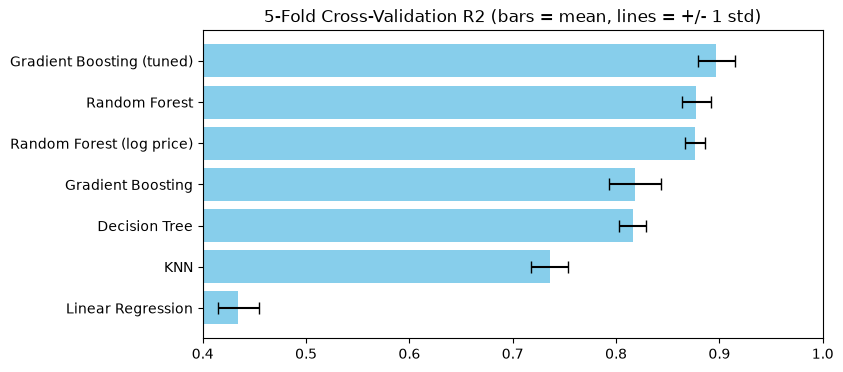

In [48]:
cv_sorted = cv_results.sort_values('CV R2 (mean)')
plt.figure(figsize=(8,4))
plt.barh(cv_sorted['Model'], cv_sorted['CV R2 (mean)'], xerr=cv_sorted['CV R2 (std)'], color='skyblue', capsize=4)
plt.title('5-Fold Cross-Validation R2 (bars = mean, lines = +/- 1 std)')
plt.xlim(0.4, 1)
plt.show()

**Cross-validation result:** the **tuned Gradient Boosting (0.897)** is the best, ahead of Random Forest (0.878). The gap (about 0.02) is bigger than the variation between folds (std 0.014 to 0.018), so it is a real difference, not luck. The default Gradient Boosting (0.818) was much worse than the tuned one, because 100 shallow trees are too simple for this data. Training Random Forest on **log(price)** gave the same R² (0.876) but the **lowest average error (MAE Rs 659)**, because it makes fewer big mistakes on the many normal-priced tickets. Linear Regression (0.43) and KNN (0.74) are clearly behind.

The cross-validated R² for Random Forest (0.878) is a bit lower than its single test split (0.891), so **cross-validation is the more honest estimate**.

## Hyperparameter Tuning
So far the models used hand-picked settings. Here we search for better settings in a structured way:
1. **GridSearchCV** on Random Forest: try every combination of `n_estimators` and `max_depth`.
2. **RandomizedSearchCV** on Random Forest: try 20 random combinations from a wider range of settings.
3. **RandomizedSearchCV** on **HistGradientBoosting**, a faster version of Gradient Boosting. Boosting builds trees one after another, each fixing the mistakes of the previous ones, unlike Random Forest which builds independent trees and averages them.

All searches use **only the training data** with 3-fold cross-validation and are scored on R². The test set is kept aside for the final comparison.

*Note: this section takes several minutes to run.*

In [49]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import randint, loguniform

cv3 = KFold(n_splits=3, shuffle=True, random_state=42)

# 1. Grid search: n_estimators x max_depth
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                       param_grid={'n_estimators': [100, 300, 500], 'max_depth': [6, 10, 15, 20, 30, None]},
                       scoring='r2', cv=cv3)
rf_grid.fit(X_train, y_train)
print('Best settings :', rf_grid.best_params_)
print('Best CV R2    :', round(rf_grid.best_score_, 4))

Best settings : {'max_depth': 30, 'n_estimators': 500}
Best CV R2    : 0.8385


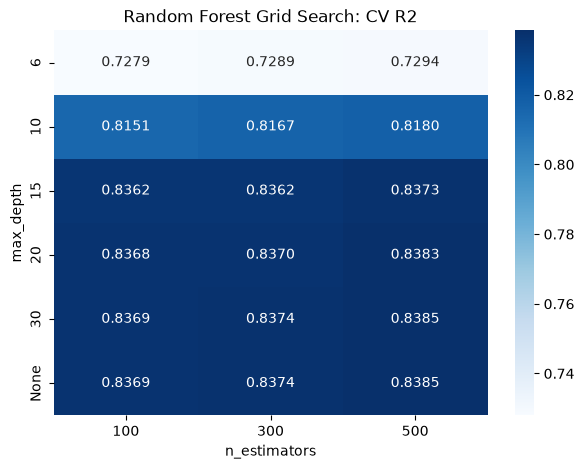

In [50]:
grid_table = pd.DataFrame(rf_grid.cv_results_)
grid_table['max_depth'] = grid_table['param_max_depth'].apply(lambda d: 'None' if pd.isna(d) else str(int(d)))   # so that None is shown too
grid_table = grid_table.pivot_table(index='max_depth', columns='param_n_estimators', values='mean_test_score')
grid_table = grid_table.reindex(['6', '10', '15', '20', '30', 'None'])

plt.figure(figsize=(7,5))
sns.heatmap(grid_table, annot=True, fmt='.4f', cmap='Blues')
plt.title('Random Forest Grid Search: CV R2')
plt.xlabel('n_estimators')
plt.show()

In [51]:
# 2. Randomized search on Random Forest (wider range of settings)
rf_random = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                               param_distributions={'n_estimators': randint(200, 600),
                                                    'max_depth': [10, 15, 20, 30, None],
                                                    'min_samples_leaf': randint(1, 10),
                                                    'max_features': ['sqrt', 'log2', 0.5, 0.7, 1.0]},
                               n_iter=20, scoring='r2', cv=cv3, random_state=42)
rf_random.fit(X_train, y_train)
print('Best settings :', rf_random.best_params_)
print('Best CV R2    :', round(rf_random.best_score_, 4))

Best settings : {'max_depth': 30, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 513}
Best CV R2    : 0.8384


In [52]:
# 3. Randomized search on HistGradientBoosting
hgb_random = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=42, early_stopping=False),
                                param_distributions={'learning_rate': loguniform(0.01, 0.3),
                                                     'max_iter': randint(200, 1000),
                                                     'max_depth': [4, 6, 8, 10, None],
                                                     'max_leaf_nodes': randint(15, 127),
                                                     'min_samples_leaf': randint(2, 50),
                                                     'l2_regularization': loguniform(0.001, 10)},
                                n_iter=30, scoring='r2', cv=cv3, random_state=42)
hgb_random.fit(X_train, y_train)
print('Best settings :', hgb_random.best_params_)
print('Best CV R2    :', round(hgb_random.best_score_, 4))

Best settings : {'l2_regularization': np.float64(0.0019870215385428634), 'learning_rate': np.float64(0.28691395365453726), 'max_depth': 4, 'max_iter': 847, 'max_leaf_nodes': 102, 'min_samples_leaf': 12}
Best CV R2    : 0.8765


## Ensembles Beyond Bagging
Random Forest is a **bagging** ensemble (many trees on random samples, averaged). We also try two ways of combining *different kinds* of models:
- **Voting:** average the predictions of the tuned Random Forest, the tuned HistGradientBoosting and the tuned Gradient Boosting.
- **Stacking:** the base models (tuned Random Forest, tuned HistGradientBoosting, Extra Trees and KNN) make predictions, and a Ridge regression **meta-model** learns how much to trust each one.

Both use **shuffled** folds, so each fold has a fair mix of dates, routes and airlines.

In [53]:
from sklearn.ensemble import VotingRegressor, StackingRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge

voting = VotingRegressor([('rf', rf_random.best_estimator_), ('hgb', hgb_random.best_estimator_),
                          ('gb', cv_models['Gradient Boosting (tuned)'])])
voting.fit(X_train, y_train)

stacking = StackingRegressor([('rf', rf_random.best_estimator_), ('hgb', hgb_random.best_estimator_),
                              ('et', ExtraTreesRegressor(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)),
                              ('knn', make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)))],
                             final_estimator=Ridge(), cv=KFold(n_splits=5, shuffle=True, random_state=42))
stacking.fit(X_train, y_train)
print('Stacking weights (rf, hgb, et, knn):', stacking.final_estimator_.coef_.round(2))

Stacking weights (rf, hgb, et, knn): [ 0.    0.65  0.44 -0.08]


### Comparing the tuned models and ensembles
We compare them on the **test set** and with **5-fold cross-validation** on the full data. Besides R² and MAE we show the share of test tickets whose predicted price is **within 10% of the real price**, which is what matters to a customer using the model.

In [54]:
def within_pct(y_true, pred, pct):
    return (np.abs(pred - np.asarray(y_true)) / np.asarray(y_true) <= pct / 100).mean() * 100

# the hand-picked models were trained on scaled data, the tuned ones on the original data
final_models = {
    'Random Forest (hand-picked)': (cv_models['Random Forest'], models['Random Forest'], X_test_s),
    'Random Forest (grid search)': (rf_grid.best_estimator_, rf_grid.best_estimator_, X_test),
    'Random Forest (random search)': (rf_random.best_estimator_, rf_random.best_estimator_, X_test),
    'HistGradientBoosting (random search)': (hgb_random.best_estimator_, hgb_random.best_estimator_, X_test),
    'Voting': (voting, voting, X_test),
    'Stacking': (stacking, stacking, X_test),
}
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
tuned = []
for name, (unfitted, fitted, X_eval) in final_models.items():
    pred = fitted.predict(X_eval)
    cv_r2 = cross_val_score(unfitted, X, y, cv=cv5, scoring='r2')
    tuned.append([name, r2_score(y_test, pred), mean_absolute_error(y_test, pred),
                  within_pct(y_test, pred, 10), cv_r2.mean(), cv_r2.std()])

tuned = pd.DataFrame(tuned, columns=['Model', 'Test R2', 'Test MAE', '% within 10% of price', 'CV R2 (mean)', 'CV R2 (std)'])
tuned.sort_values('CV R2 (mean)', ascending=False).round(4)

,Model,Test R2,Test MAE,% within 10% of price,CV R2 (mean),CV R2 (std)
5,Stacking,0.9116,702.6049,74.1042,0.9065,0.0137
4,Voting,0.9147,675.1570,75.4897,0.9053,0.0118
3,HistGradientBoosting (random search),0.9057,781.6529,68.0841,0.9002,0.0173
0,Random Forest (hand-picked),0.8908,704.4426,75.5375,0.8777,0.0137
1,Random Forest (grid search),0.8909,704.1464,75.7286,0.8772,0.0140
2,Random Forest (random search),0.8910,704.0509,75.8242,0.8771,0.0141


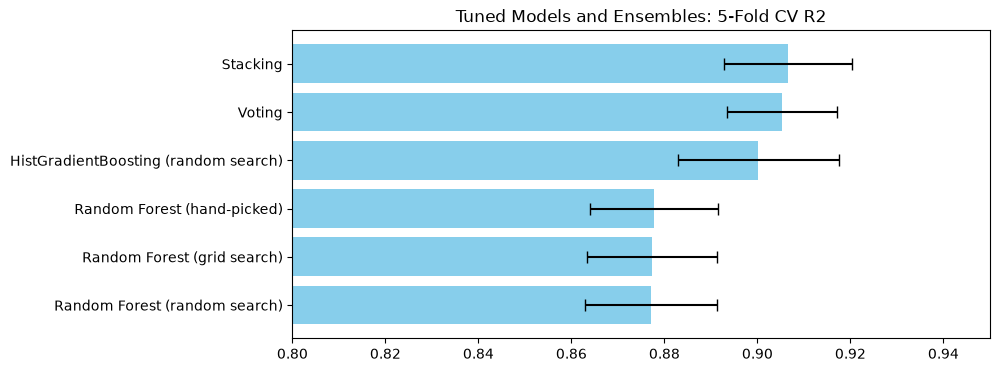

In [55]:
tuned_sorted = tuned.sort_values('CV R2 (mean)')
plt.figure(figsize=(9,4))
plt.barh(tuned_sorted['Model'], tuned_sorted['CV R2 (mean)'], xerr=tuned_sorted['CV R2 (std)'], color='skyblue', capsize=4)
plt.title('Tuned Models and Ensembles: 5-Fold CV R2')
plt.xlim(0.8, 0.95)
plt.show()

In [56]:
# same flight (airline, date, route, departure time) but different prices in the data
same_flight = df.groupby(['Airline', 'Date_of_Journey', 'Route', 'Dep_Time'])['Price'].agg(['count', 'nunique', 'min', 'max'])
repeated = same_flight[same_flight['count'] > 1]
print('Flights that appear more than once      :', len(repeated))
print('...of which have more than one price    :', (repeated['nunique'] > 1).sum())
print('Median gap between highest and lowest   :', (repeated['max'] - repeated['min'])[repeated['nunique'] > 1].median())

Flights that appear more than once      : 1907
...of which have more than one price    : 1602
Median gap between highest and lowest   : 2031.0


**Tuning result: tuning Random Forest did not help, but boosting and combining models did.**

**What the grid search showed (`n_estimators` x `max_depth`):**
- **`max_depth` matters a lot, `n_estimators` does not.** Shallow trees are far too simple (depth 6: CV R² 0.729, depth 10: 0.818). The score keeps rising up to depth 15 (0.837) and then levels off: depth 20, 30 and unlimited all score about **0.838**.
- Going from 100 to 500 trees changes the score by only about 0.002, so more trees only make training slower.
- Unlike many datasets, **deep trees are not overfitting here**: many tickets are the same flight sold again at a similar price, so a deep tree that "remembers" a flight is often right. The best settings (unlimited depth) are the **same as the hand-picked Random Forest**, so the search confirms our original choice.
- *(These scores are lower than the 0.878 in the 5-fold check because 3-fold CV on the training set trains each model on only about 5,600 rows instead of about 8,400.)*

**What the randomized searches found:**
- **Random Forest** (20 combinations, also trying `min_samples_leaf` and `max_features`): best was depth 30, `min_samples_leaf` 1, all features, CV R² 0.838. **No better than the grid search.**
- **HistGradientBoosting** (30 combinations): best was about 850 small trees (depth 4) with a fast learning rate (0.29), CV R² **0.877**, clearly better than Random Forest (0.838) on the same folds.

**Ensembles beyond bagging:**
- **Stacking** gave most weight to HistGradientBoosting (0.65) and Extra Trees (0.44), and **zero weight to Random Forest**, because Extra Trees already gives the same kind of predictions. KNN got a small negative weight (-0.08), meaning it adds almost nothing.
- **Voting** (plain average of tuned Random Forest, HistGradientBoosting and Gradient Boosting) got the **highest test R² (0.915), the lowest test MAE (Rs 675)** and 75.5% of predictions within 10% of the real price.

**Final comparison:**
- The three Random Forests are all at **0.877** CV R², so tuning Random Forest changed nothing.
- **HistGradientBoosting (0.900), Voting (0.905) and Stacking (0.907)** are about **0.03 higher**, which is about twice the normal variation between folds (std 0.012-0.017). So unlike Random Forest tuning, **this is a real improvement**.
- Stacking and Voting are **tied** (difference 0.001, much smaller than the std). Voting wins on the test set (R² 0.915 vs 0.912, MAE Rs 675 vs 703).
- HistGradientBoosting alone has a good R² but only **68% of predictions within 10%**, compared with about 75% for Random Forest and Voting. Random Forest is very good at prices it has seen before; boosting is better on unusual tickets. **Voting combines both strengths.**
- *(The tuned settings were chosen using the training rows, which are also part of the 5-fold CV, so the tuned CV scores may be slightly optimistic. The untouched test set confirms the same order: Voting 0.915 vs Random Forest 0.891.)*

**Why the score stops at about 0.91:** **1,602 flights appear more than once with different prices** (same airline, date, route and departure time), with a median gap of **Rs 2,031**. The price depends on **when the ticket was bought**, and the booking date is not in the data. No model can predict this part, so to improve further we would need new information such as the booking date or the number of seats left, not a more complex model.

**Decision:** use the **Voting model** (average of tuned Random Forest, HistGradientBoosting and Gradient Boosting). It has the best test R², the lowest error and ties for the best CV score. It is simpler than stacking (a plain average, no meta-model), and each of its three parts is a standard, well-understood model.

Test R2  : 0.915
Test MAE : 675 Rs
Test RMSE: 1329 Rs
Test MAPE: 7.9 %


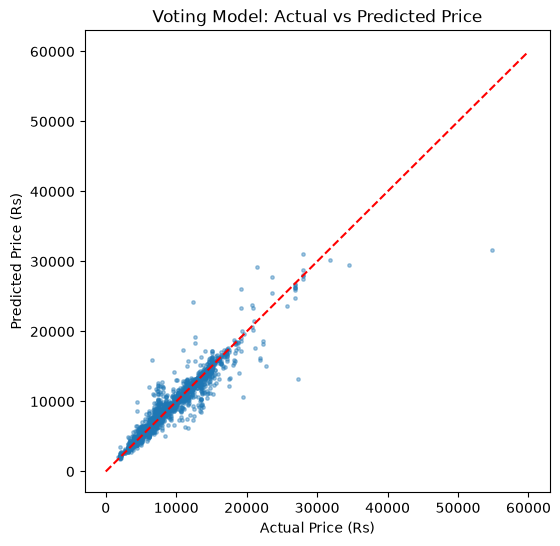

In [57]:
from sklearn.inspection import permutation_importance

best = voting
pred = best.predict(X_test)
print('Test R2  :', round(r2_score(y_test, pred), 3))
print('Test MAE :', round(mean_absolute_error(y_test, pred)), 'Rs')
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_test, pred))), 'Rs')
print('Test MAPE:', round(mean_absolute_percentage_error(y_test, pred) * 100, 1), '%')

plt.figure(figsize=(6,6))
plt.scatter(y_test, pred, s=6, alpha=0.4)
plt.plot([0, 60000], [0, 60000], color='red', linestyle='--')
plt.title('Voting Model: Actual vs Predicted Price')
plt.xlabel('Actual Price (Rs)')
plt.ylabel('Predicted Price (Rs)')
plt.show()

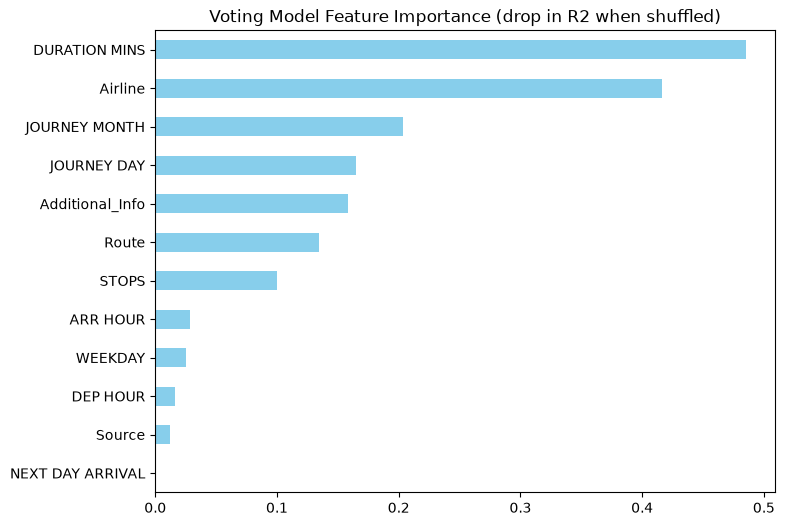

In [58]:
# the voting model has no feature_importances_, so use permutation importance:
# shuffle one column at a time and see how much the test R2 drops
perm = permutation_importance(best, X_test, y_test, scoring='r2', n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values()
importance.plot(kind='barh', color='skyblue', figsize=(8,6))
plt.title('Voting Model Feature Importance (drop in R2 when shuffled)')
plt.show()

In [59]:
# how close are the predictions to the real price?
for pct in [5, 10, 20, 30]:
    print(f'Predictions within {pct}% of the real price: {within_pct(y_test, pred, pct):.1f}%')

# median error by route
err = pd.DataFrame({'route': df.loc[y_test.index, 'ROUTE NAME'], 'actual': y_test, 'predicted': pred})
err['abs % error'] = (err['predicted'] - err['actual']).abs() / err['actual'] * 100
err.groupby('route')['abs % error'].median().round(1)

Predictions within 5% of the real price: 54.4%
Predictions within 10% of the real price: 75.5%
Predictions within 20% of the real price: 91.0%
Predictions within 30% of the real price: 95.7%


route
Banglore - Delhi      4.8
Chennai - Kolkata     3.4
Delhi - Cochin        4.8
Kolkata - Banglore    3.3
Mumbai - Hyderabad    6.4
Name: abs % error, dtype: float64

In [60]:
# some example predictions for tickets the model has never seen
sample = df.loc[y_test.index, ['Airline', 'Date_of_Journey', 'ROUTE NAME', 'Total_Stops', 'Dep_Time']].copy()
sample['ACTUAL PRICE'] = y_test
sample['PREDICTED PRICE'] = pred.round(0).astype(int)
sample.sample(10, random_state=3)

,Airline,Date_of_Journey,ROUTE NAME,Total_Stops,Dep_Time,ACTUAL PRICE,PREDICTED PRICE
4583,Multiple carriers,6/06/2019,Delhi - Cochin,1 stop,04:55,10678,10170
4361,IndiGo,1/04/2019,Kolkata - Banglore,1 stop,21:00,5930,6504
6838,IndiGo,18/05/2019,Delhi - Cochin,1 stop,07:35,6442,6867
8238,Jet Airways,21/05/2019,Delhi - Cochin,2 stops,05:30,15129,14809
796,Jet Airways,9/04/2019,Banglore - Delhi,non-stop,07:10,7229,7227
9956,Jet Airways,21/06/2019,Mumbai - Hyderabad,non-stop,19:35,3210,3478
8538,Jet Airways,24/06/2019,Delhi - Cochin,2 stops,19:30,10368,10091
1120,Air India,24/06/2019,Mumbai - Hyderabad,non-stop,21:05,3100,2755
3191,Jet Airways,24/03/2019,Kolkata - Banglore,1 stop,21:10,13759,13664
399,Air India,6/06/2019,Kolkata - Banglore,2 stops,16:50,11432,11477


**Result:** the **Voting model** is the best model, with a test **R² of 0.915**: it explains about 91% of the variation in price for tickets it has never seen. Its average error (MAE) is **Rs 675**, or **7.9%** of the ticket price (MAPE). **54% of predictions are within 5%** of the real price, **75.5% within 10%** and **91% within 20%**. It is accurate on every route, with a median error between **3.3% (Kolkata to Banglore) and 6.4% (Mumbai to Hyderabad)**. The example predictions above show how close it gets, e.g. Rs 7,227 predicted vs Rs 7,229 real for a Jet Airways Banglore to Delhi flight.

It is clearly better than the best single model from the first comparison (Random Forest, test R² 0.891, CV 0.878). Hyperparameter tuning (GridSearchCV, RandomizedSearchCV) did not improve Random Forest, but tuned boosting and combining models raised the CV R² from 0.878 to about 0.905.

The feature importance chart shows that **flight duration** and the **airline** matter most, followed by the **journey date (month and day)**, **additional info** (e.g. business class or no check-in baggage), the **route** and the **number of stops**. Departure and arrival hour, weekday and source city matter much less.

**Value for customers:** a traveller can enter the airline, date, route, stops and times and get a price estimate that is within 10% of the real fare 3 times out of 4. This helps them **plan their journey**: spot a fare that is much higher than expected, and compare different airlines, dates or non-stop options before booking.

# Part 3: Suggestions for Travellers

## How can customers get a cheaper ticket?

In [61]:
# cheapest airline on each route (median price, airlines with at least 20 flights on that route)
route_air = df.groupby(['ROUTE NAME', 'Airline'])['Price'].agg(['count', 'median'])
route_air = route_air[route_air['count'] >= 20].reset_index()
route_air.pivot_table(index='Airline', columns='ROUTE NAME', values='median').round(0)

ROUTE NAME,Banglore - Delhi,Chennai - Kolkata,Delhi - Cochin,Kolkata - Banglore,Mumbai - Hyderabad
Airline,,,,,
Air Asia,4282.0,NaN,6752.0,4409.0,NaN
Air India,7276.0,4667.0,9653.0,10676.0,3100.0
GoAir,3898.0,NaN,5842.0,7102.0,NaN
IndiGo,4823.0,3854.0,6494.0,4804.0,3175.0
Jet Airways,8016.0,NaN,12898.0,11467.0,5678.0
Multiple carriers,NaN,NaN,10197.0,NaN,NaN
SpiceJet,3971.0,3597.0,5583.0,3873.0,2017.0
Vistara,5403.0,5944.0,6216.0,8820.0,12395.0


In [62]:
# non-stop vs stops on the same route
df.pivot_table(index='ROUTE NAME', columns='Total_Stops', values='Price', aggfunc='median').reindex(
    columns=['non-stop', '1 stop', '2 stops', '3 stops'])

Total_Stops,non-stop,1 stop,2 stops,3 stops
ROUTE NAME,,,,
Banglore - Delhi,4823.0,12284.0,12358.0,13081.0
Chennai - Kolkata,3850.0,NaN,NaN,NaN
Delhi - Cochin,6094.0,9646.0,13013.5,10703.0
Kolkata - Banglore,4409.0,10844.0,12224.0,13007.0
Mumbai - Hyderabad,3175.0,12395.0,16172.0,16276.5


In [63]:
# check: early-March flights look expensive, but is this only because of the route mix?
# compare each route's median price by journey period
df['JOURNEY PERIOD'] = pd.cut(date, bins=pd.to_datetime(['2019-02-28', '2019-03-14', '2019-03-31', '2019-04-30', '2019-06-30']),
                              labels=['1-12 Mar', '15-27 Mar', 'April', 'May-June'])
df.pivot_table(index='ROUTE NAME', columns='JOURNEY PERIOD', values='Price', aggfunc='median')

JOURNEY PERIOD,1-12 Mar,15-27 Mar,April,May-June
ROUTE NAME,,,,
Banglore - Delhi,12778.0,7832.0,4823.0,4823.0
Chennai - Kolkata,7295.0,3858.5,NaN,3597.0
Delhi - Cochin,14871.0,7934.0,5947.0,10262.0
Kolkata - Banglore,4778.0,10031.0,4804.0,9931.5
Mumbai - Hyderabad,12080.0,2754.0,2754.0,3100.0


In [64]:
# within the same route, how much cheaper or dearer is each period than that route's usual price?
df['VS ROUTE MEDIAN %'] = (df['Price'] / df.groupby('ROUTE NAME')['Price'].transform('median') - 1) * 100
df.groupby('JOURNEY PERIOD')['VS ROUTE MEDIAN %'].median().round(1)

JOURNEY PERIOD
1-12 Mar     63.6
15-27 Mar    -2.5
April       -28.1
May-June      0.0
Name: VS ROUTE MEDIAN %, dtype: float64

In [65]:
# departure time of day, compared within the same route
df['TIME OF DAY'] = pd.cut(df['DEP HOUR'], bins=[-1, 5, 11, 17, 23], labels=['Night (0-5)', 'Morning (6-11)', 'Afternoon (12-17)', 'Evening (18-23)'])
df.groupby('TIME OF DAY')['VS ROUTE MEDIAN %'].agg(['count', 'median']).round(1)

,count,median
TIME OF DAY,,
Night (0-5),1046,-2.2
Morning (6-11),4224,0.0
Afternoon (12-17),2562,0.0
Evening (18-23),2629,0.0


In [66]:
# weekday, compared within the same route
df.groupby('WEEKDAY')['VS ROUTE MEDIAN %'].agg(['count', 'median']).round(1).reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

,count,median
WEEKDAY,,
Monday,1807,-6.6
Tuesday,853,3.4
Wednesday,2047,-5.0
Thursday,1774,-1.7
Friday,908,12.0
Saturday,1623,0.0
Sunday,1449,12.8


In [67]:
# fares with no check-in baggage vs normal fares on the same airline and route
bag = df[df['Airline'].isin(df.loc[df['Additional_Info'] == 'No check-in baggage included', 'Airline'].unique())]
bag = bag.assign(FARE=np.where(bag['Additional_Info'] == 'No check-in baggage included', 'no check-in bag', 'normal fare'))
bag.pivot_table(index=['Airline', 'ROUTE NAME'], columns='FARE', values='Price', aggfunc='median').dropna().round(0)

FARE                         no check-in bag  normal fare
Airline  ROUTE NAME                                      
SpiceJet Banglore - Delhi             3919.0       4377.0
         Chennai - Kolkata            3543.0       3597.0
         Delhi - Cochin               5158.0       5583.0
         Kolkata - Banglore           3841.0       4174.0
         Mumbai - Hyderabad           1965.0       2017.0

In [68]:
# premium / business tickets
df[df['Airline'].str.contains('Business|Premium')].groupby('Airline')['Price'].agg(['count', 'median', 'max'])

,count,median,max
Airline,,,
Jet Airways Business,6,54747.0,79512
Multiple carriers Premium economy,13,11269.0,14629
Vistara Premium economy,3,9125.0,11793


## Suggestions for Travellers

**A note on fair comparison:** the 5 routes have very different prices (median Rs 3,276 for Mumbai to Hyderabad vs Rs 10,262 for Delhi to Cochin), and some dates and airlines have mostly cheap or mostly expensive routes. So the suggestions below compare tickets **on the same route**, using each ticket's price compared with its route's median price (`VS ROUTE MEDIAN %`).

### 1. Choose a low-cost airline
| Route | Cheapest airline | Jet Airways | Air India |
|---|---|---|---|
| Banglore - Delhi | GoAir Rs 3,898 / SpiceJet Rs 3,971 | Rs 8,016 | Rs 7,276 |
| Delhi - Cochin | **SpiceJet Rs 5,583** | Rs 12,898 | Rs 9,653 |
| Kolkata - Banglore | **SpiceJet Rs 3,873** | Rs 11,467 | Rs 10,676 |
| Mumbai - Hyderabad | **SpiceJet Rs 2,017** | Rs 5,678 | Rs 3,100 |
| Chennai - Kolkata | **SpiceJet Rs 3,597** | – | Rs 4,667 |

* **SpiceJet is the cheapest or almost the cheapest on every route**, followed by IndiGo, GoAir and Air Asia.
* **Jet Airways usually costs 2 to 3 times more** on the same route. Vistara is cheap on Delhi to Cochin (Rs 6,216) but expensive on Mumbai to Hyderabad (Rs 12,395).

---

### 2. Take a non-stop flight: it is both faster and cheaper
| Route | Non-stop | 1 stop | 2 stops |
|---|---|---|---|
| Banglore - Delhi | **Rs 4,823** | Rs 12,284 | Rs 12,358 |
| Delhi - Cochin | **Rs 6,094** | Rs 9,646 | Rs 13,014 |
| Kolkata - Banglore | **Rs 4,409** | Rs 10,844 | Rs 12,224 |
| Mumbai - Hyderabad | **Rs 3,175** | Rs 12,395 | Rs 16,172 |

* On every route, a flight with stops costs **1.6 to 5 times more** than a non-stop flight. Stopover flights are mostly sold by full-service airlines (Jet Airways, Air India, Multiple carriers), so a stop does not save money here.

---

### 3. Don't book at the last minute, and travel off-peak if you can
| Journey period | Price vs the route's usual price |
|---|---|
| 1-12 March | **+63.6%** |
| 15-27 March | -2.5% |
| April | **-28.1%** |
| May-June | 0.0% |

* On the same route, journeys on **1-12 March cost about 64% more** than usual (e.g. Banglore to Delhi Rs 12,778 vs Rs 4,823 later). These are the earliest dates in the data, so they were most likely bought **only a few days before the flight**, when fares are highest. (The booking date is not in the data, so this is the most likely reason, not a proven one. Kolkata to Banglore is the one exception.)
* **April is the cheapest time to fly (28% below usual)**. May and June (summer holidays) are back to normal prices.
* **Suggestion:** book a few weeks ahead, and pick April-type off-peak periods when your plans are flexible.

---

### 4. Fly on a Monday or Wednesday
* On the same route, **Sunday (+12.8%) and Friday (+12.0%)** are the most expensive days, when people travel for weekends.
* **Monday (-6.6%) and Wednesday (-5.0%)** are the cheapest. Moving a trip from Sunday to Monday saves almost 20%.

---

### 5. The time of day matters less than it looks
* The overall chart shows late-night flights as much cheaper, but **on the same route, night flights (midnight-5 am) are only 2.2% cheaper**. Morning, afternoon and evening flights cost the same. The low overall price was mostly because many night flights are on cheaper routes. Don't take an uncomfortable night flight just to save money.

---

### 6. Travel light
* SpiceJet's **"no check-in baggage" fares are 1-10% cheaper** than its normal fares on the same route (e.g. Delhi to Cochin Rs 5,158 vs Rs 5,583). If you only have hand luggage, choose this fare.

---

### 7. Use the model before booking
* Enter the airline, date, route, stops and times to get a predicted fare. **75% of predictions are within 10% of the real price**. If the price you are offered is much higher than the prediction, compare other airlines, days or a non-stop option before booking.

### Summary
To get a cheaper ticket, travellers should **choose a low-cost airline (SpiceJet, IndiGo, GoAir, Air Asia)**, **take a non-stop flight**, **avoid last-minute bookings**, **travel in off-peak periods like April**, **fly on Monday or Wednesday instead of Friday or Sunday**, **choose a hand-luggage-only fare when possible** and **check the model's predicted price before booking**.

# Model Comparison Report

**Goal:** Predict the **price of a flight ticket** (a number, in rupees) from the airline, journey date, route, stops, departure and arrival time, duration and additional information. The data has 10,461 rows (after removing duplicates, the missing row and the impossible 5-minute flight), split 80% for training and 20% for testing.

| Model | Train R² | Test R² | MAE (Rs) | RMSE (Rs) | MAPE |
|---|---|---|---|---|---|
| **Random Forest** | 0.979 | **0.891** | **704** | **1,503** | **8.1%** |
| Gradient Boosting | 0.841 | 0.830 | 1,230 | 1,875 | 15.1% |
| Decision Tree | 0.911 | 0.811 | 915 | 1,976 | 10.3% |
| KNN | 0.838 | 0.746 | 1,390 | 2,291 | 17.9% |
| Linear Regression | 0.431 | 0.454 | 2,484 | 3,361 | 32.9% |

*R² = how much of the variation in price the model explains (1.0 is perfect, 0 is no better than always guessing the average). MAE = average error in rupees. RMSE = like MAE but punishes big mistakes more. MAPE = average error as a percentage of the ticket price.*

**5-fold cross-validation (more reliable than one split)**

| Model | CV R² (mean) | CV R² (std) | CV MAE (Rs) |
|---|---|---|---|
| **Gradient Boosting (tuned)** | **0.897** | 0.018 | 693 |
| Random Forest | 0.878 | 0.014 | 675 |
| Random Forest (log price) | 0.876 | 0.009 | **659** |
| Gradient Boosting | 0.818 | 0.025 | 1,249 |
| Decision Tree | 0.816 | 0.014 | 896 |
| KNN | 0.736 | 0.018 | 1,376 |
| Linear Regression | 0.434 | 0.020 | 2,474 |

**Hyperparameter Tuning & Advanced Ensembles**

| Model | How it was built | Test R² | Test MAE (Rs) | % within 10% of price | CV R² (mean) |
|---|---|---|---|---|---|
| Stacking | RF + HGB + Extra Trees + KNN, Ridge meta-model | 0.912 | 703 | 74.1% | **0.907** |
| **Voting** | average of tuned RF + HGB + GB | **0.915** | **675** | 75.5% | 0.905 |
| HistGradientBoosting (random search) | 30 random combinations | 0.906 | 782 | 68.1% | 0.900 |
| Random Forest (hand-picked) | 300 trees, unlimited depth | 0.891 | 704 | 75.5% | 0.878 |
| Random Forest (grid search) | `n_estimators` x `max_depth`, 18 combinations | 0.891 | 704 | 75.7% | 0.877 |
| Random Forest (random search) | 20 random combinations | 0.891 | 704 | **75.8%** | 0.877 |

The grid search showed that Random Forest needs deep trees (depth 6: 0.729, depth 15 or more: about 0.838) and that more than 100 trees adds almost nothing. Tuning Random Forest did not improve it, but **boosting and the two ensembles improved CV R² by about 0.03**, about twice the variation between folds. Voting and Stacking are tied on CV, and Voting is better on the test set.

**How each model performed**
- **Linear Regression (R² 0.45):** the weakest. It assumes each feature adds a fixed amount to the price, but the real patterns are combinations (e.g. Jet Airways is expensive on some routes and not on others), and label-encoded airline and route numbers have no real order. Its average error is about Rs 2,500 (33%).
- **KNN (R² 0.75):** better, but it treats every feature as equally important when measuring "closeness", so unimportant columns like departure hour confuse it.
- **Decision Tree (R² 0.81):** captures combinations, but a single tree is unstable and its predictions jump in steps.
- **Gradient Boosting (default, R² 0.83):** 100 shallow trees are too simple for this data. **Tuned (500 trees, depth 6) it jumps to 0.897 CV**, the best single model in cross-validation.
- **Random Forest (R² 0.89, CV 0.878):** the best of the first five on the test set, with the lowest error. Its train R² (0.98) is much higher than its test R² (0.89), but the grid search showed that limiting the depth makes it worse, because many tickets are repeat sales of the same flight.
- **HistGradientBoosting (CV 0.900):** a high R², but fewer predictions within 10% (68%) than Random Forest.
- **Voting (CV 0.905, test 0.915):** combines Random Forest's accuracy on familiar flights with boosting's accuracy on unusual ones, and is best or almost best on every measure.

**Recommended Model for Production: Voting Regressor** (average of tuned Random Forest, HistGradientBoosting and Gradient Boosting)

The Voting model is chosen because:
1. It has the **highest test R² (0.915)** and the **lowest test MAE (Rs 675)**, and ties for the best cross-validated R² (0.905).
2. **75.5% of its predictions are within 10%** of the real price and 91% within 20%, which is useful for a customer checking whether a fare is fair.
3. It beats the best single model (Random Forest) by about 0.03 CV R², which is more than the normal variation between folds.
4. It is **simpler than stacking**, which scored the same: it only averages three predictions, with no meta-model to train.
5. It handles skewed prices, outliers and combinations of features without extra work, and permutation importance still shows which features drive the price.

# Report on Challenges Faced

| # | Challenge in the data | Technique used | Reason |
|---|---|---|---|
| 1 | **Excel file:** the data came as `.xlsx`, not CSV. | Used `pd.read_excel()` (installed `openpyxl`). | pandas needs the `openpyxl` package to read `.xlsx` files. |
| 2 | **Missing values:** 1 row had no `Route` and no `Total_Stops`. | Dropped the row. | It is only 1 row out of 10,683, and the number of stops is one of the most important features, so filling it with a guess would add made-up data. |
| 3 | **Duplicate rows:** 220 rows were exact copies. | Removed them with `drop_duplicates()`. | Duplicates count the same ticket twice and could end up in both train and test sets, giving a falsely good score. |
| 4 | **Same value written differently:** `'Delhi'` and `'New Delhi'`; `'No info'` and `'No Info'`. | Replaced them with one value. | Otherwise the model treats one city (or one value) as two different categories. |
| 5 | **Dates in mixed formats:** `'01/03/2019'` and `'1/03/2019'`, so 44 date strings for 40 real dates. | `pd.to_datetime(..., dayfirst=True)`, then took day, month and weekday. | The format is day/month/year; without `dayfirst`, pandas could read 03/06 as 6 March instead of 3 June. |
| 6 | **Times stored as text, and some arrival times had a date attached** (`'01:10 22 Mar'`). | Took the first 5 characters for the hour, and made a `NEXT DAY ARRIVAL` flag. | Models need numbers, and the attached date shows an overnight flight, which is useful information. |
| 7 | **Duration stored as text** (`'2h 50m'`, `'19h'`, `'5m'`). | Wrote a function to convert it into minutes. | Duration is the most important feature, so it has to be a number. Some values have only hours or only minutes, so the function handles both. |
| 8 | **Impossible value:** a 2-stop flight with a duration of 5 minutes. | Removed the row. | It is clearly a data error, and leaving it in would teach the model something wrong. |
| 9 | **Ordered text category:** `Total_Stops` (`'non-stop'`, `'1 stop'`, ...). | Mapped it by hand to 0, 1, 2, 3, 4. | LabelEncoder sorts alphabetically and would put `'non-stop'` after `'4 stops'`, losing the natural order. |
| 10 | **Redundant feature:** each `Source` always flies to the same `Destination`. | Dropped `Destination`. | It has exactly the same information as `Source`, so it adds nothing to the model. |
| 11 | **Many categories in `Route`** (128 values). | Kept it with `LabelEncoder` and used tree models. | It shows which city the flight stops in, which other columns don't show. Tree models handle a label-encoded column with many values well. |
| 12 | **Skewed target with outliers:** price skew 1.86, up to Rs 79,512 (business class). | Found outliers with the IQR method and boxplots but **kept** them. Also tried a Random Forest on **log(price)**. | They are real tickets, not errors. The log version gave the same R² (0.876) but a lower average error (Rs 659), showing the skew does not hurt tree models much. |
| 13 | **Rare categories:** Trujet (1 ticket), Jet Airways Business (6), Vistara Premium economy (3). | Kept them. | They are real tickets. Predictions for these rare types are less reliable because the model has very few examples to learn from. |
| 14 | **Non-linear patterns:** e.g. the same airline is cheap on one route and expensive on another. | Compared 5 algorithms; chose tree-based ensembles. | Linear Regression only explained 45% of the variation (R² 0.45) because it can't capture combinations of features. Trees can. |
| 15 | **Overfitting:** Random Forest had train R² 0.98 but test R² 0.89. | Used an 80/20 train/test split and **5-fold cross-validation** to measure the real performance. | Testing on unseen data shows the true performance. |
| 16 | **Hand-picked settings might not be the best.** | **GridSearchCV** (`n_estimators` x `max_depth`) and **RandomizedSearchCV** (Random Forest and HistGradientBoosting), using only the training data and 3-fold CV. | A structured search shows whether better settings exist. It showed that Random Forest was already at its best, and found much better settings for boosting. |
| 17 | **Choosing between close models.** | Compared the tuned models and ensembles with 5-fold CV and the test set, looking at R², MAE and % within 10%. | A single split can favour a model by luck. Using several measures shows that the Voting model is best overall, not just on one number. |
| 18 | **The same flight has different prices:** 1,602 flights appear with more than one price (median gap Rs 2,031). | Accepted it as a limit of the data and explained it. | The price depends on **when the ticket was bought**, which is not in the data. No model can predict this part, so it limits how accurate any model can be. |
| 19 | **Misleading group comparisons:** e.g. April tickets are mostly on cheaper routes, and night flights are often on cheaper routes. | Created a `VS ROUTE MEDIAN %` column and compared each group **within the same route**. | Without this, flights leaving around midnight look about half the price; on the same route, night flights are only 2% cheaper. This makes sure the suggestions to travellers are based on real differences. |